# GEC-RAG Project
## Notebook 02 — ERRANT Annotation Pipeline

This notebook runs **standard ERRANT 3.0.0** from scratch on the raw `.orig` and `.corr` sentence pairs from the Write & Improve Corpus 2024.

**Goals:**
- Produce fine-grained error type classifications (e.g. `R:VERB:TENSE`, `M:ART`, `R:PREP`)
- Replace the coarse `OTHER` categories from the pre-existing M2 files
- Generate a clean annotated dataset ready for RAG Knowledge Base construction (Notebook 03)

**Output:** A new `.m2` file and a structured CSV of all error instances with fine-grained types.

---
### Cell 1 — Install & Verify ERRANT

In [2]:
import subprocess, sys

# Install ERRANT and spacy model if not already present
subprocess.run([sys.executable, '-m', 'pip', 'install', 'errant', '-q'])
subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm', '-q'])

# Verify
import errant
print(f'✅ ERRANT version: {errant.__version__}')

import spacy
nlp = spacy.load('en_core_web_sm')
print(f'✅ spaCy model loaded: en_core_web_sm')

✅ ERRANT version: 3.0.2
✅ spaCy model loaded: en_core_web_sm


---
### Cell 2 — Imports & Paths

In [3]:
import errant
import pandas as pd
import numpy as np
import os
import json
import matplotlib.pyplot as plt
from collections import Counter
from tqdm.notebook import tqdm
import warnings
warnings.filterwarnings('ignore')

subprocess_result = __import__('subprocess').run(
    [sys.executable, '-m', 'pip', 'install', 'tqdm', '-q']
)

# ⚠️ Update BASE_DIR to match your actual path from Notebook 01
BASE_DIR           = 'C:/gecrag'
DATA_DIR           = os.path.join(BASE_DIR, 'data/write_and_improve')
FINAL_VERSIONS_DIR = os.path.join(DATA_DIR, 'user-prompt-final-versions')
RESULTS_DIR        = os.path.join(BASE_DIR, 'results')
KB_DIR             = os.path.join(BASE_DIR, 'knowledge_base')

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(KB_DIR,      exist_ok=True)

print('✅ Imports successful')
print(f'✅ Directories ready')

✅ Imports successful
✅ Directories ready


---
### Cell 3 — Locate Raw Sentence Pair Files

In [4]:
# List all files to find exact .orig and .corr filenames
print('Files in user-prompt-final-versions:')
all_files = []
for f in sorted(os.listdir(FINAL_VERSIONS_DIR)):
    full_path = os.path.join(FINAL_VERSIONS_DIR, f)
    if os.path.isfile(full_path):
        size = os.path.getsize(full_path)
        all_files.append(f)
        print(f'   {f:<50} ({size/1024:.1f} KB)')
    else:
        print(f'   📁 {f}/')

# Auto-detect .orig and .corr files
orig_files = [f for f in all_files if f.endswith('.orig')]
corr_files = [f for f in all_files if f.endswith('.corr')]
print(f'\n✅ Found .orig files: {orig_files}')
print(f'✅ Found .corr files: {corr_files}')

Files in user-prompt-final-versions:
   en-writeandimprove2024-final-versions-dev-essays.conll (833.2 KB)
   en-writeandimprove2024-final-versions-dev-essays.m2 (826.0 KB)
   en-writeandimprove2024-final-versions-dev-sentences.conll (771.1 KB)
   en-writeandimprove2024-final-versions-dev-sentences.corr (423.0 KB)
   en-writeandimprove2024-final-versions-dev-sentences.ids (97.8 KB)
   en-writeandimprove2024-final-versions-dev-sentences.m2 (895.1 KB)
   en-writeandimprove2024-final-versions-dev-sentences.orig (419.2 KB)
   en-writeandimprove2024-final-versions-m2-essay-info.tsv (617.8 KB)
   en-writeandimprove2024-final-versions-m2-sentence-info.tsv (11388.4 KB)
   en-writeandimprove2024-final-versions-orig-dev.md  (438.1 KB)
   en-writeandimprove2024-final-versions-orig-dev.tmp (428.6 KB)
   en-writeandimprove2024-final-versions-orig-test.md (463.1 KB)
   en-writeandimprove2024-final-versions-orig-test.tmp (454.0 KB)
   en-writeandimprove2024-final-versions-orig-train.md (3374.6 KB)
   

---
### Cell 4 — Load Sentence Pairs
> ⚠️ Update filenames below if Cell 3 shows different names

In [5]:
def load_text_file(filepath):
    """Load plain text file, one item per line"""
    with open(filepath, 'r', encoding='utf-8') as f:
        lines = [line.strip() for line in f.readlines() if line.strip()]
    return lines

# Use train split for building the RAG KB
# ⚠️ Adjust filenames based on Cell 3 output if needed
SPLIT = 'en-writeandimprove2024-final-versions-train-sentences'  # change to 'dev' if train files not available

orig_path = os.path.join(FINAL_VERSIONS_DIR, f'{SPLIT}.orig')
corr_path = os.path.join(FINAL_VERSIONS_DIR, f'{SPLIT}.corr')

try:
    orig_sentences = load_text_file(orig_path)
    corr_sentences = load_text_file(corr_path)

    # Ensure equal length
    assert len(orig_sentences) == len(corr_sentences), \
        f'Length mismatch: {len(orig_sentences)} orig vs {len(corr_sentences)} corr'

    print(f'✅ Loaded {SPLIT} split')
    print(f'   Sentence pairs: {len(orig_sentences)}')
    print(f'\nSample pairs:')
    for i in range(3):
        print(f'\n  [{i+1}] ORIG : {orig_sentences[i]}')
        print(f'       CORR : {corr_sentences[i]}')

except FileNotFoundError as e:
    print(f'❌ {e}')
    print(f'👉 Update SPLIT or filenames based on Cell 3 output')
except AssertionError as e:
    print(f'❌ {e}')

✅ Loaded en-writeandimprove2024-final-versions-train-sentences split
   Sentence pairs: 37486

Sample pairs:

  [1] ORIG : New Year is always an invite to establish goals for the next 365 days.
       CORR : A new year is always an invitation to establish goals for the next 365 days.

  [2] ORIG : There are some areas there I'm pleased like improving my idioms knowledge, writing, speaking, presenting scientific articles.
       CORR : There are some areas that I'm pleased with, like my knowledge of languages, writing, speaking, and presenting scientific articles.

  [3] ORIG : There are also areas that I should improve like statistics, IA, algorithms and how to present a work I developed.
       CORR : There are also areas that I should improve, like statistics, AI, algorithms, and how to present a project I have developed.


---
### Cell 5 — Initialize ERRANT Annotator

In [6]:
import errant

# Load ERRANT annotator
annotator = errant.load('en')
print('✅ ERRANT annotator loaded')

# Quick sanity check
test_orig = annotator.parse('I go to school yesterday .')
test_corr = annotator.parse('I went to school yesterday .')
test_edits = annotator.annotate(test_orig, test_corr)

print('\n🔍 Sanity check:')
print(f'   Original : I go to school yesterday .')
print(f'   Corrected: I went to school yesterday .')
print(f'   Detected edits:')
for edit in test_edits:
    print(f'      Type: {edit.type:<20} '
          f'Original: "{edit.o_str}" → Correction: "{edit.c_str}"')

✅ ERRANT annotator loaded

🔍 Sanity check:
   Original : I go to school yesterday .
   Corrected: I went to school yesterday .
   Detected edits:
      Type: R:VERB:TENSE         Original: "go" → Correction: "went"


---
### Cell 6 — Run ERRANT Annotation Pipeline
> ⏳ This cell will take several minutes depending on corpus size. Progress bar will show.

In [7]:
def annotate_sentence_pairs(orig_list, corr_list, annotator, max_sentences=None):
    """
    Run ERRANT annotation on a list of original/corrected sentence pairs.
    
    Returns:
        List of dicts with error annotations per sentence pair
    """
    results = []
    errors  = 0

    # Optionally limit for testing
    n = max_sentences if max_sentences else len(orig_list)
    orig_list = orig_list[:n]
    corr_list = corr_list[:n]

    for idx, (orig, corr) in enumerate(tqdm(
        zip(orig_list, corr_list),
        total=len(orig_list),
        desc='Annotating'
    )):
        try:
            orig_parsed = annotator.parse(orig)
            corr_parsed = annotator.parse(corr)
            edits       = annotator.annotate(orig_parsed, corr_parsed)

            edit_list = []
            for edit in edits:
                if edit.type != 'noop':
                    edit_list.append({
                        'error_type'  : edit.type,
                        'original'    : edit.o_str,
                        'correction'  : edit.c_str,
                        'start'       : edit.o_start,
                        'end'         : edit.o_end,
                    })

            results.append({
                'idx'      : idx,
                'original' : orig,
                'corrected': corr,
                'edits'    : edit_list,
                'n_errors' : len(edit_list)
            })

        except Exception as e:
            errors += 1
            results.append({
                'idx'      : idx,
                'original' : orig,
                'corrected': corr,
                'edits'    : [],
                'n_errors' : 0,
                'error'    : str(e)
            })

    print(f'\n✅ Annotation complete')
    print(f'   Processed  : {len(results)} sentence pairs')
    print(f'   Errors     : {errors} (skipped)')
    print(f'   With edits : {sum(1 for r in results if r["n_errors"] > 0)}')
    print(f'   No edits   : {sum(1 for r in results if r["n_errors"] == 0)}')

    return results


# Run annotation
# ⚠️ For a quick test, set max_sentences=500
# ⚠️ For full run, set max_sentences=None
print('Starting ERRANT annotation...')
print('(For a quick test run first, set max_sentences=500)\n')

annotated = annotate_sentence_pairs(
    orig_sentences,
    corr_sentences,
    annotator,
    max_sentences=None  # ⚠️ Change to None for full run after test succeeds
)

Starting ERRANT annotation...
(For a quick test run first, set max_sentences=500)



Annotating:   0%|          | 0/37486 [00:00<?, ?it/s]


✅ Annotation complete
   Processed  : 37486 sentence pairs
   Errors     : 0 (skipped)
   With edits : 23266
   No edits   : 14220


---
### Cell 7 — Flatten to DataFrame

In [8]:
# Flatten nested edits into one row per error instance
rows = []
for sentence in annotated:
    for edit in sentence['edits']:
        rows.append({
            'sentence_idx' : sentence['idx'],
            'original_sent': sentence['original'],
            'corrected_sent': sentence['corrected'],
            'error_type'   : edit['error_type'],
            'original_span': edit['original'],
            'correction'   : edit['correction'],
            'start_pos'    : edit['start'],
            'end_pos'      : edit['end'],
        })

df_errors = pd.DataFrame(rows)

print(f'✅ Error DataFrame created')
print(f'   Total error instances: {len(df_errors)}')
print(f'   Unique error types   : {df_errors["error_type"].nunique()}')
print(f'\nSample rows:')
print(df_errors[['error_type', 'original_span', 'correction', 'original_sent']].head(10).to_string())

✅ Error DataFrame created
   Total error instances: 62752
   Unique error types   : 51

Sample rows:
  error_type      original_span               correction                                                                                                                  original_sent
0      M:DET                New                    A new                                                         New Year is always an invite to establish goals for the next 365 days.
1     R:ORTH               Year                     year                                                         New Year is always an invite to establish goals for the next 365 days.
2    R:MORPH             invite               invitation                                                         New Year is always an invite to establish goals for the next 365 days.
3    R:OTHER              there                     that  There are some areas there I'm pleased like improving my idioms knowledge, writing, speaking, presenting 

---
### Cell 8 — Error Type Distribution (Fine-Grained)

Total error types (all)     : 51
Specific error types        : 48
OTHER variants              : 3
Specific errors (count)     : 50164
OTHER errors (count)        : 12588
% specific of total         : 79.9%


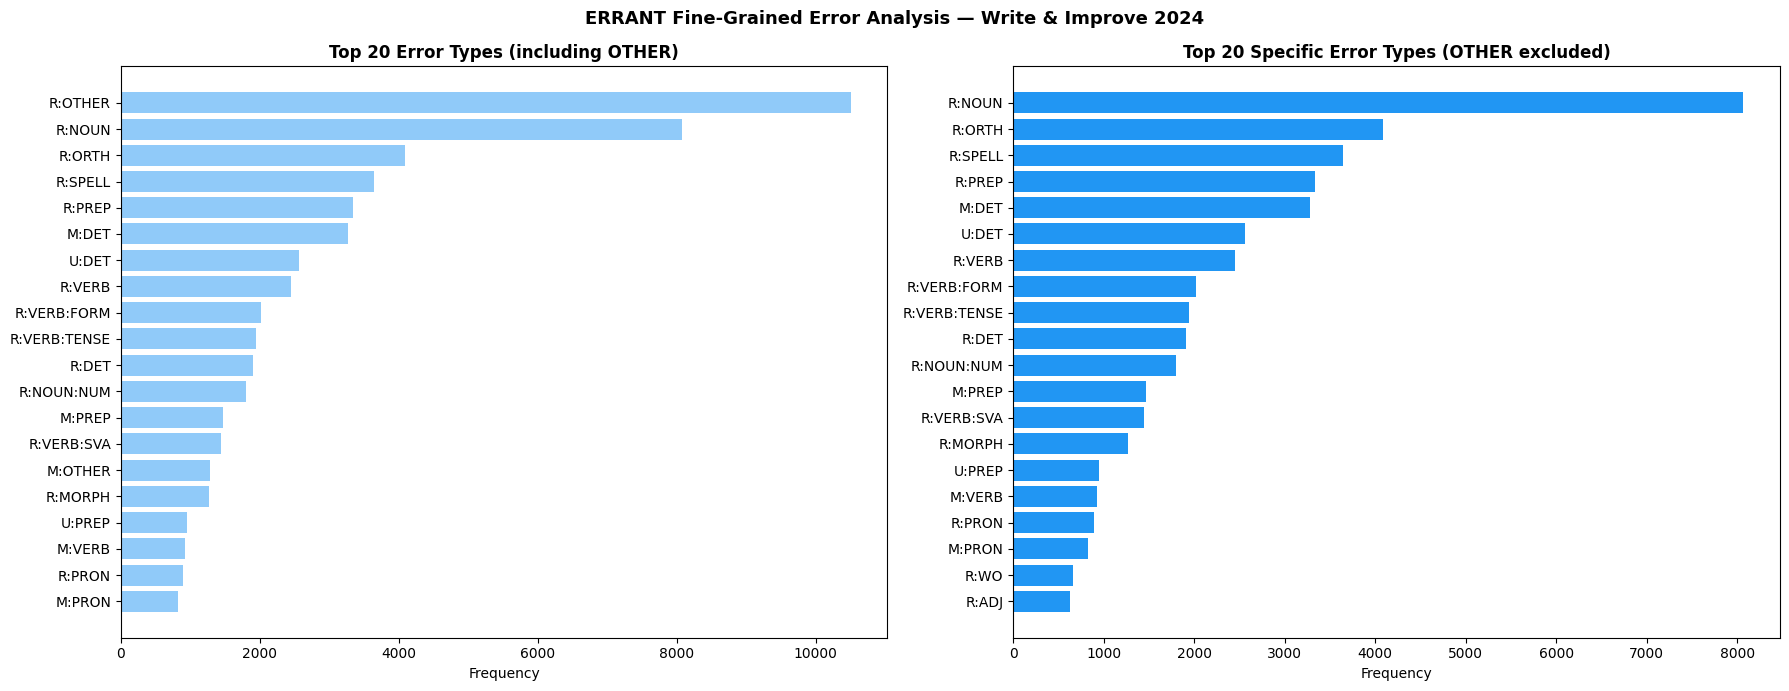


Top Specific Error Types:
Error Type                   Count   % of Specific
--------------------------------------------------
R:NOUN                        8069           16.1%
R:ORTH                        4089            8.2%
R:SPELL                       3647            7.3%
R:PREP                        3337            6.7%
M:DET                         3273            6.5%
U:DET                         2562            5.1%
R:VERB                        2453            4.9%
R:VERB:FORM                   2022            4.0%
R:VERB:TENSE                  1938            3.9%
R:DET                         1903            3.8%
R:NOUN:NUM                    1800            3.6%
M:PREP                        1469            2.9%
R:VERB:SVA                    1440            2.9%
R:MORPH                       1270            2.5%
U:PREP                         945            1.9%
M:VERB                         919            1.8%
R:PRON                         889            1.8%
M:PR

In [9]:
error_counts = df_errors['error_type'].value_counts()

# Filter out OTHER for cleaner analysis
specific_errors = error_counts[~error_counts.index.str.contains('OTHER')]
other_errors    = error_counts[error_counts.index.str.contains('OTHER')]

print(f'Total error types (all)     : {len(error_counts)}')
print(f'Specific error types        : {len(specific_errors)}')
print(f'OTHER variants              : {len(other_errors)}')
print(f'Specific errors (count)     : {specific_errors.sum()}')
print(f'OTHER errors (count)        : {other_errors.sum()}')
print(f'% specific of total         : {specific_errors.sum()/len(df_errors)*100:.1f}%')

# Plot top specific error types
top_specific = specific_errors.head(20)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# All errors including OTHER
top_all = error_counts.head(20)
axes[0].barh(top_all.index[::-1], top_all.values[::-1], color='#90CAF9')
axes[0].set_title('Top 20 Error Types (including OTHER)',
                  fontweight='bold')
axes[0].set_xlabel('Frequency')

# Specific errors only
axes[1].barh(top_specific.index[::-1], top_specific.values[::-1], color='#2196F3')
axes[1].set_title('Top 20 Specific Error Types (OTHER excluded)',
                  fontweight='bold')
axes[1].set_xlabel('Frequency')

plt.suptitle('ERRANT Fine-Grained Error Analysis — Write & Improve 2024',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'errant_finegrained_errors.png'),
            dpi=150, bbox_inches='tight')
plt.show()

print(f'\nTop Specific Error Types:')
print(f'{"Error Type":<25} {"Count":>8} {"% of Specific":>15}')
print('-' * 50)
for err, count in top_specific.items():
    pct = count / specific_errors.sum() * 100
    print(f'{err:<25} {count:>8} {pct:>14.1f}%')

---
### Cell 9 — Extract & Inspect Error Examples per Type

In [10]:
def show_error_examples(df, error_type, n=5):
    """Show example sentences for a given error type"""
    subset = df[df['error_type'] == error_type].head(n)
    separator = '='*60
    dash = '-'*55
    print(f'\n{separator}')
    print(f'Error Type: {error_type} ({len(df[df["error_type"]==error_type])} instances)')
    print(separator)
    for _, row in subset.iterrows():
        print(f'  Original span : "{row["original_span"]}"')
        print(f'  Correction    : "{row["correction"]}"')
        print(f'  In sentence   : {row["original_sent"][:100]}...')
        print(f'  {dash}')

# Show examples for the most pedagogically relevant error types
priority_types = [
    'R:VERB:TENSE',
    'R:VERB:SVA',
    'M:DET',
    'R:DET',
    'U:DET',
    'M:PREP',
    'R:PREP',
    'R:MORPH',
    'R:NOUN:NUM',
]

available_types = df_errors['error_type'].unique()
print('Checking which priority error types are present in this sample...')
for t in priority_types:
    count = len(df_errors[df_errors['error_type'] == t])
    status = '✅' if count > 0 else '❌'
    print(f'  {status} {t:<25} ({count} instances)')

# Show examples for available types
for t in priority_types:
    if t in available_types:
        show_error_examples(df_errors, t, n=3)

Checking which priority error types are present in this sample...
  ✅ R:VERB:TENSE              (1938 instances)
  ✅ R:VERB:SVA                (1440 instances)
  ✅ M:DET                     (3273 instances)
  ✅ R:DET                     (1903 instances)
  ✅ U:DET                     (2562 instances)
  ✅ M:PREP                    (1469 instances)
  ✅ R:PREP                    (3337 instances)
  ✅ R:MORPH                   (1270 instances)
  ✅ R:NOUN:NUM                (1800 instances)

Error Type: R:VERB:TENSE (1938 instances)
  Original span : "left"
  Correction    : "leave"
  In sentence   : I'll left key to my house in your post box as usually....
  -------------------------------------------------------
  Original span : "have seen"
  Correction    : "saw"
  In sentence   : I have seen it on Monday in the cinema....
  -------------------------------------------------------
  Original span : "change"
  Correction    : "have changed"
  In sentence   : During the last 100 years people

---
### Cell 10 — Save Annotated Dataset

In [11]:
# Save full error DataFrame
errors_csv_path = os.path.join(RESULTS_DIR, 'errant_annotations.csv')
df_errors.to_csv(errors_csv_path, index=False)
print(f'✅ Full annotations saved: {errors_csv_path}')

# Save specific errors only (no OTHER) — this is what we use for RAG KB
df_specific = df_errors[~df_errors['error_type'].str.contains('OTHER')].copy()
specific_csv_path = os.path.join(RESULTS_DIR, 'errant_annotations_specific.csv')
df_specific.to_csv(specific_csv_path, index=False)
print(f'✅ Specific annotations saved: {specific_csv_path}')

# Save error type summary
summary_df = df_errors['error_type'].value_counts().reset_index()
summary_df.columns = ['error_type', 'count']
summary_df['percentage'] = (summary_df['count'] / len(df_errors) * 100).round(2)
summary_df['is_specific'] = ~summary_df['error_type'].str.contains('OTHER')
summary_path = os.path.join(RESULTS_DIR, 'errant_error_summary.csv')
summary_df.to_csv(summary_path, index=False)
print(f'✅ Error summary saved: {summary_path}')

# Save annotated sentences as JSON for Notebook 03
json_path = os.path.join(KB_DIR, 'annotated_sentences.json')
with open(json_path, 'w', encoding='utf-8') as f:
    json.dump(annotated, f, ensure_ascii=False, indent=2)
print(f'✅ Annotated sentences saved: {json_path}')

✅ Full annotations saved: C:/gecrag\results\errant_annotations.csv
✅ Specific annotations saved: C:/gecrag\results\errant_annotations_specific.csv
✅ Error summary saved: C:/gecrag\results\errant_error_summary.csv
✅ Annotated sentences saved: C:/gecrag\knowledge_base\annotated_sentences.json


---
### Cell 11 — Summary Report

In [12]:
print('=' * 60)
print('ERRANT ANNOTATION SUMMARY')
print('=' * 60)

print(f'\n📊 Corpus Coverage:')
print(f'   Sentence pairs processed : {len(annotated)}')
print(f'   Pairs with errors        : {sum(1 for r in annotated if r["n_errors"] > 0)}')
print(f'   Pairs without errors     : {sum(1 for r in annotated if r["n_errors"] == 0)}')
avg_errors = np.mean([r["n_errors"] for r in annotated])
print(f'   Avg errors per sentence  : {avg_errors:.2f}')

print(f'\n📊 Error Statistics:')
print(f'   Total error instances    : {len(df_errors)}')
print(f'   Unique error types       : {df_errors["error_type"].nunique()}')
print(f'   Specific (non-OTHER)     : {len(df_specific)}')
print(f'   OTHER (catch-all)        : {len(df_errors) - len(df_specific)}')

print(f'\n📊 Top 10 Specific Error Types (for RAG KB):')
print(f'   {"Error Type":<25} {"Count":>8}')
print(f'   {"-"*35}')
for err, count in specific_errors.head(10).items():
    print(f'   {err:<25} {count:>8}')

print(f'\n📁 Output Files:')
print(f'   - results/errant_annotations.csv')
print(f'   - results/errant_annotations_specific.csv')
print(f'   - results/errant_error_summary.csv')
print(f'   - results/errant_finegrained_errors.png')
print(f'   - knowledge_base/annotated_sentences.json')

print(f'\n➡️  Next: Run Notebook 03 — RAG Knowledge Base Construction')
print(f'\n⚠️  Reminder: If you ran with max_sentences=500 (test run),')
print(f'   go back to Cell 6, set max_sentences=None, and re-run')
print(f'   cells 6-11 for the full corpus before proceeding.')

ERRANT ANNOTATION SUMMARY

📊 Corpus Coverage:
   Sentence pairs processed : 37486
   Pairs with errors        : 23266
   Pairs without errors     : 14220
   Avg errors per sentence  : 1.67

📊 Error Statistics:
   Total error instances    : 62752
   Unique error types       : 51
   Specific (non-OTHER)     : 50164
   OTHER (catch-all)        : 12588

📊 Top 10 Specific Error Types (for RAG KB):
   Error Type                   Count
   -----------------------------------
   R:NOUN                        8069
   R:ORTH                        4089
   R:SPELL                       3647
   R:PREP                        3337
   M:DET                         3273
   U:DET                         2562
   R:VERB                        2453
   R:VERB:FORM                   2022
   R:VERB:TENSE                  1938
   R:DET                         1903

📁 Output Files:
   - results/errant_annotations.csv
   - results/errant_annotations_specific.csv
   - results/errant_error_summary.csv
   - result